In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
import os

# Define the path to the zip file and the directory to extract to
zip_file_path = '/content/drive/MyDrive/Clonedqrdetector/datasets/qrCodes.zip'
extract_dir = '/content/extractedqrCodes'

# Create the extraction directory if it doesn't exist
os.makedirs(extract_dir, exist_ok=True)

print(f"Extracting '{zip_file_path}' to '{extract_dir}'...")

Extracting '/content/drive/MyDrive/Clonedqrdetector/datasets/qrCodes.zip' to '/content/extractedqrCodes'...


In [ ]:
!unzip -q "/content/drive/MyDrive/Clonedqrdetector/datasets/qrCodes.zip" -d "/content/extractedqrCodes"
print("Extraction complete.")

Extraction complete.


In [ ]:
!ls -F /content/extractedqrCodes

qrCodes/


In [ ]:
import os
import cv2
import numpy as np
import random
import shutil
from google.colab import files

In [ ]:
# This will force-delete the old generated folders and zip files
!rm -rf class0 class1 dataset
!rm -f Medishare_Dataset_Class0.zip Medishare_Dataset_Class1.zip
!rm -f /content/drive/MyDrive/Clonedqrdetector/datasets/Medishare_Dataset_Class0.zip
!rm -f /content/drive/MyDrive/Clonedqrdetector/datasets/Medishare_Dataset_Class1.zip

print("Old data wiped! Safe to generate the new dataset.")

Old data wiped! Safe to generate the new dataset.


In [ ]:
def setup_directories(base_dir="qrCodes", class0_dir="class0", class1_dir="class1"):
    if not os.path.exists(base_dir):
        print(f"Error: The folder '{base_dir}' does not exist.")
        return False
    os.makedirs(class0_dir, exist_ok=True)
    os.makedirs(class1_dir, exist_ok=True)
    return True

In [ ]:
def generate_class0_fake(img, output_path):
    blurred = cv2.GaussianBlur(img, (3, 3), 0)
    alpha = 0.8
    beta = 10
    faded = cv2.convertScaleAbs(blurred, alpha=alpha, beta=beta)
    cv2.imwrite(output_path, faded)

In [ ]:
import cv2
import numpy as np
import random

def generate_class1_authentic(img, output_path, num_dots=150):
    """
    Simulates the authentic Medishare QR code.
    Injects EXACTLY 150 covert micro-dots at 5% to 10% black intensity.
    """
    secure_img = img.copy()

    # Faint gray intensity (5% to 10% black)
    min_intensity = int(255 * (1 - 0.10))  # 229
    max_intensity = int(255 * (1 - 0.05))  # 242

    # Find coordinates of all white pixels
    y_coords, x_coords = np.where(secure_img > 245)
    white_pixels = list(zip(y_coords, x_coords))

    # Fallback just in case there aren't enough white pixels
    if len(white_pixels) < num_dots:
        num_dots = len(white_pixels)

    # Randomly pick exactly 150 unique locations
    chosen_pixels = random.sample(white_pixels, num_dots)

    # Inject the dots
    for y, x in chosen_pixels:
        secure_img[y, x] = random.randint(min_intensity, max_intensity)

    cv2.imwrite(output_path, secure_img)

In [ ]:
def process_and_download_dataset():
    input_folder = "/content/extractedqrCodes/qrCodes"  # Corrected path
    class0_folder = "class0"
    class1_folder = "class1"

    if not setup_directories(input_folder, class0_folder, class1_folder):
        # This line will now correctly check for the existence of /content/extractedqrCodes/qrCodes
        print("Please create the 'qr_codes' folder and upload your images first.")
        return

    valid_extensions = ('.png', '.jpg', '.jpeg')
    image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(valid_extensions)]

    if len(image_files) == 0:
        print(f"No images found in '{input_folder}'.")
        return

    print(f"Found {len(image_files)} images. Generating dataset...")

    count = 0
    for filename in image_files:
        in_path = os.path.join(input_folder, filename)
        img = cv2.imread(in_path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            continue

        out_path_class0 = os.path.join(class0_folder, f"fake_{filename}")
        out_path_class1 = os.path.join(class1_folder, f"auth_{filename}")

        generate_class0_fake(img, out_path_class0)
        generate_class1_authentic(img, out_path_class1)

        count += 1

    print("Dataset Generation Complete!")

    # --- Save to Google Drive ---s
    print("Zipping files...")
    shutil.make_archive("Medishare_Dataset_Class0", 'zip', "class0")
    shutil.make_archive("Medishare_Dataset_Class1", 'zip', "class1")

    # Define the destination path in Google Drive
    drive_output_dir = "/content/drive/MyDrive/Clonedqrdetector/datasets/"
    os.makedirs(drive_output_dir, exist_ok=True) # Ensure the directory exists

    # Move the zipped files to Google Drive
    shutil.move("Medishare_Dataset_Class0.zip", os.path.join(drive_output_dir, "Medishare_Dataset_Class0.zip"))
    shutil.move("Medishare_Dataset_Class1.zip", os.path.join(drive_output_dir, "Medishare_Dataset_Class1.zip"))

    print(f"Dataset zips saved to {drive_output_dir}")

In [ ]:
process_and_download_dataset()

Found 6636 images. Generating dataset...
Dataset Generation Complete!
Zipping files...
Dataset zips saved to /content/drive/MyDrive/Clonedqrdetector/datasets/


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
import os
import zipfile

# Create master dataset folder
os.makedirs("dataset/fake", exist_ok=True)       # Class 0
os.makedirs("dataset/authentic", exist_ok=True)  # Class 1

drive_path = "/content/drive/MyDrive/Clonedqrdetector/datasets/"

# Unzip Class 0 (Fake/Cloned)
with zipfile.ZipFile(os.path.join(drive_path, "Medishare_Dataset_Class0.zip"), 'r') as zip_ref:
    zip_ref.extractall("dataset/fake/")

# Unzip Class 1 (Authentic/Micro-dots)
with zipfile.ZipFile(os.path.join(drive_path, "Medishare_Dataset_Class1.zip"), 'r') as zip_ref:
    zip_ref.extractall("dataset/authentic/")

print("Data unzipped and organized successfully!")

Data unzipped and organized successfully!


In [ ]:
from torch.utils.data import random_split
import time
import copy

In [ ]:
import torch
import torchvision.transforms as transforms

# ---------------------------------------------------------
# Custom Transform: Add Random Camera Sensor Noise
# ---------------------------------------------------------
class AddGaussianNoise(object):
    """
    Saste smartphone cameras ki sensor noise ko simulate karta hai.
    Isse CNN seekhta hai ki 'random camera noise' aur
    'real micro-dots' ke beech ka difference kya hai.
    """
    def __init__(self, mean=0., std=0.05, p=0.5):
        self.std = std
        self.mean = mean
        self.p = p # Noise apply hone ki probability

    def __call__(self, tensor):
        if torch.rand(1).item() < self.p:
            noise = torch.randn(tensor.size()) * self.std + self.mean
            return torch.clamp(tensor + noise, 0., 1.) # Pixel values ko valid range mein rakhta hai
        return tensor

# ---------------------------------------------------------
# The Upgraded Transform Dictionary
# ---------------------------------------------------------
IMAGE_SIZE = 224

data_transforms = {
    'train': transforms.Compose([
        # 1. Spatial/Geometric Difficulty
    # Zoom aur crop ko thoda kam aggressive kiya hai (0.8 se 0.85)
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.85, 1.0)),

    # Rotation 30 se kam karke 15 degrees kar diya hai (Normal hand shake, extreme angle nahi)
    transforms.RandomRotation(15),

    # Perspective distortion kam kiya hai (0.3 -> 0.2)
    transforms.RandomPerspective(distortion_scale=0.2, p=0.4),

    # 2. Photometric/Lighting Difficulty
    # Normal room lighting variations (0.3 -> 0.2)
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),

    # 3. Focus Difficulty
    # Blur ka kernel size aur intensity (sigma) dono kam kiye hain taaki 150 dots completely wash out na hon
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 1.0))
    ], p=0.2), # Probability bhi 30% se 20% kar di

    transforms.ToTensor(),

    # 4. Sensor Noise Difficulty
    # Sabse bada factor: Noise 8% se girakar 5% (0.05) kar di gayi hai.
    AddGaussianNoise(std=0.05, p=0.4),

    # Standard ImageNet Normalization
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),

    # Validation set hamesha clean rehna chahiye. Isme koi extreme augmentation nahi hoga.
    'val': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

In [ ]:
# ---------------------------------------------------------
# 3. Load Data & Create Train/Validation Splits
# ---------------------------------------------------------
from torch.utils.data import random_split # Added this import

# Load all images
DATA_DIR = "dataset/"
full_dataset = datasets.ImageFolder(DATA_DIR, transform=data_transforms['train'])

# Split into 80% Training and 20% Validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Note: We need to override the transform for the validation set so it doesn't get augmented
val_dataset.dataset.transform = data_transforms['val']

BATCH_SIZE = 32 # Define BATCH_SIZE

dataloaders = {
    'train': DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2),
    'val': DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
}

dataset_sizes = {'train': train_size, 'val': val_size}
class_names = full_dataset.classes # ['authentic', 'fake']
print(f"Classes detected: {class_names}")

Classes detected: ['authentic', 'fake']


In [ ]:
# Define easy and hard transforms for curriculum learning
# Easy transforms (minimal augmentation)
easy_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Hard transforms (full augmentation from data_transforms['train'])
hard_transforms = data_transforms['train']

print("Curriculum transforms defined: easy_transforms and hard_transforms")

Curriculum transforms defined: easy_transforms and hard_transforms


In [ ]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 14.0 MB/s eta 0:00:00


In [ ]:
import torch.nn as nn
import torch.optim as optim

class MicroDotCNN_UltraSimple(nn.Module):
    def __init__(self):
        super(MicroDotCNN_UltraSimple, self).__init__()

        self.features = nn.Sequential(
            # Block 1 (Input: 3x224x224 -> Output: 16x112x112)
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 2 (Input: 16x112x112 -> Output: 32x56x56)
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 3 (Input: 32x56x56 -> Output: 64x28x28)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)

            # Block 4 yahan se remove kar diya gaya hai
        )

        # Final classification head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            # Updated math: 64 channels * 28 width * 28 height
            nn.Linear(64 * 28 * 28, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Initialize the model
# Assuming 'device' is already defined (cuda or cpu)
model = MicroDotCNN_UltraSimple().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [ ]:

criterion = nn.CrossEntropyLoss()


In [ ]:
def train_curriculum_model(model, criterion, optimizer, num_epochs=30): # Max epochs set to 30
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    patience = 4 # Number of epochs to wait for improvement before stopping

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)
        print(" Curriculum: HARD MODE (Adding noise, blur, and rotation!)")
        print(" Reducing Learning Rate to prevent Catastrophic Forgetting...")

        # --- THE NEW FIX: LEARNING RATE DECAY ---
        for param_group in optimizer.param_groups:
            param_group['lr'] = 0.0001 # Take smaller steps now!
        train_dataset.dataset.transform = hard_transforms
        # REFRESH the dataloader so PyTorch is forced to use the Hard transforms
        dataloaders['train'] = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)


        # --- THE FIX: FORCING THE DATALOADER TO UPDATE ---
        #if epoch == 0:
            #print(" Curriculum: EASY MODE (Learning the micro-dots)")
            #train_dataset.dataset.transform = easy_transforms
            # Initialize easy dataloader (num_workers=0 ensures no caching bugs)
            #dataloaders['train'] = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)

        #elif epoch == 5:
            # THIS IS WHERE IT WILL PRINT!
            #print(" Curriculum: HARD MODE (Adding noise, blur, and rotation!)")
            #print(" Reducing Learning Rate to prevent Catastrophic Forgetting...")

            # --- THE NEW FIX: LEARNING RATE DECAY ---
            #for param_group in optimizer.param_groups:
                #param_group['lr'] = 0.0001 # Take smaller steps now!
            #train_dataset.dataset.transform = hard_transforms
            # REFRESH the dataloader so PyTorch is forced to use the Hard transforms
            #dataloaders['train'] = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
        # ------------------------------------------------

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val':
                if epoch_acc > best_acc:
                    best_acc = epoch_acc
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0
                else:
                    epochs_no_improve += 1
                    print(f'Early stopping check: No improvement for {epochs_no_improve} epochs.')

        if epochs_no_improve >= patience:
            print(f'Early stopping! Validation accuracy has not improved for {patience} epochs.')
            model.load_state_dict(best_model_wts)
            break

    print(f'\nTraining complete! Best Validation Accuracy: {best_acc:4f}')
    model.load_state_dict(best_model_wts) # Load best model weights
    return model

# Train the model again
model1 = train_curriculum_model(model, criterion, optimizer, num_epochs=50)


Epoch 1/50
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.2925 Acc: 0.8759
Val Loss: 0.1589 Acc: 0.9427

Epoch 2/50
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.1751 Acc: 0.9323
Val Loss: 0.1204 Acc: 0.9488

Epoch 3/50
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.1201 Acc: 0.9557
Val Loss: 0.0991 Acc: 0.9593

Epoch 4/50
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.1239 Acc: 0.9537
Val Loss: 0.0965 Acc: 0.9638

Epoch 5/50
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.1192 Acc: 0.9587
Val Loss:

In [ ]:
import torch
import os

# Define the path where you want to save the model in Google Drive
model_save_path = '/content/drive/MyDrive/Clonedqrdetector/best_microdot_cnn_model.pth'

# Ensure the directory exists
os.makedirs(os.path.dirname(model_save_path), exist_ok=True)

# Save the model's state dictionary
torch.save(model1.state_dict(), model_save_path)

print(f"Model saved successfully to: {model_save_path}")

Model saved successfully to: /content/drive/MyDrive/Clonedqrdetector/best_microdot_cnn_model.pth



--- Model Evaluation Statistics ---
Overall Accuracy: 0.9778
Weighted Precision: 0.9778
Weighted Recall: 0.9778
Weighted F1-Score: 0.9778

Classification Report:
              precision    recall  f1-score   support

   authentic       0.98      0.98      0.98      1360
        fake       0.98      0.97      0.98      1295

    accuracy                           0.98      2655
   macro avg       0.98      0.98      0.98      2655
weighted avg       0.98      0.98      0.98      2655


Confusion Matrix:
[[1334   26]
 [  33 1262]]


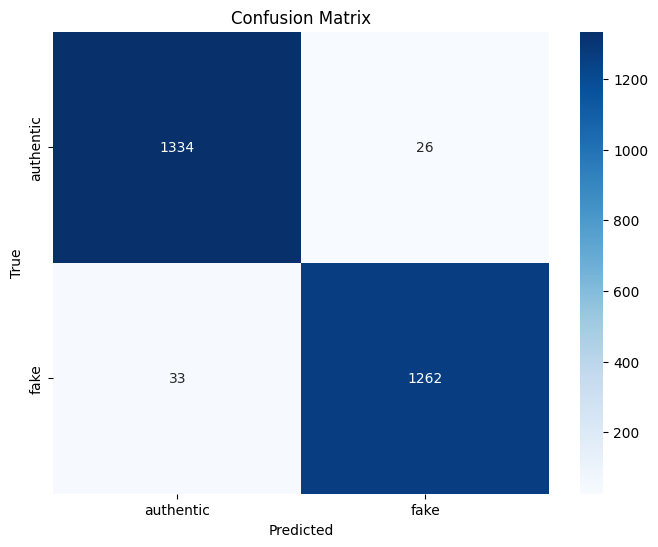

In [ ]:
import torch
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Ensure the model is in evaluation mode
model1.eval()

all_preds = []
all_labels = []

# No need to track gradients for evaluation
with torch.no_grad():
    for inputs, labels in dataloaders['val']:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model1(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convert lists to numpy arrays
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average='weighted')
recall = recall_score(all_labels, all_preds, average='weighted')
f1 = f1_score(all_labels, all_preds, average='weighted')

print(f"\n--- Model Evaluation Statistics ---")
print(f"Overall Accuracy: {accuracy:.4f}")
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall: {recall:.4f}")
print(f"Weighted F1-Score: {f1:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

# Confusion Matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(all_labels, all_preds)
print(cm)

# Optionally, display the confusion matrix with labels
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
import torch.nn as nn
import torch.optim as optim

class MicroDotCNN_FiveLayer(nn.Module):
    def __init__(self):
        super(MicroDotCNN_FiveLayer, self).__init__()

        self.features = nn.Sequential(
            # Block 1 (Input: 3x224x224 -> Output: 16x112x112)
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 2 (Input: 16x112x112 -> Output: 32x56x56)
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 3 (Input: 32x56x56 -> Output: 64x28x28)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 4 (Input: 64x28x28 -> Output: 128x14x14)
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 5 (Input: 128x14x14 -> Output: 256x7x7)
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        # Final classification head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            # Updated math: 256 channels * 7 width * 7 height
            nn.Linear(256 * 7 * 7, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Initialize model2
model2 = MicroDotCNN_FiveLayer().to(device)
optimizer2 = optim.Adam(model2.parameters(), lr=0.01)

# Train model2 with the specified parameters
model2_trained = train_curriculum_model(model2, criterion, optimizer2, num_epochs=30)

print("\nModel 2 training complete!")



Epoch 1/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.3201 Acc: 0.8629
Val Loss: 0.1516 Acc: 0.9465

Epoch 2/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.1356 Acc: 0.9457
Val Loss: 0.1013 Acc: 0.9574

Epoch 3/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.1014 Acc: 0.9597
Val Loss: 0.0732 Acc: 0.9706

Epoch 4/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.0925 Acc: 0.9626
Val Loss: 0.0826 Acc: 0.9672
Early stopping check: No improvement for 1 epochs.

Epoch 5/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic For


--- Model2 Evaluation Statistics ---
Overall Accuracy: 0.9819
Weighted Precision: 0.9821
Weighted Recall: 0.9819
Weighted F1-Score: 0.9819

Classification Report for Model2:
              precision    recall  f1-score   support

   authentic       0.99      0.97      0.98      1360
        fake       0.97      0.99      0.98      1295

    accuracy                           0.98      2655
   macro avg       0.98      0.98      0.98      2655
weighted avg       0.98      0.98      0.98      2655


Confusion Matrix for Model2:
[[1325   35]
 [  13 1282]]


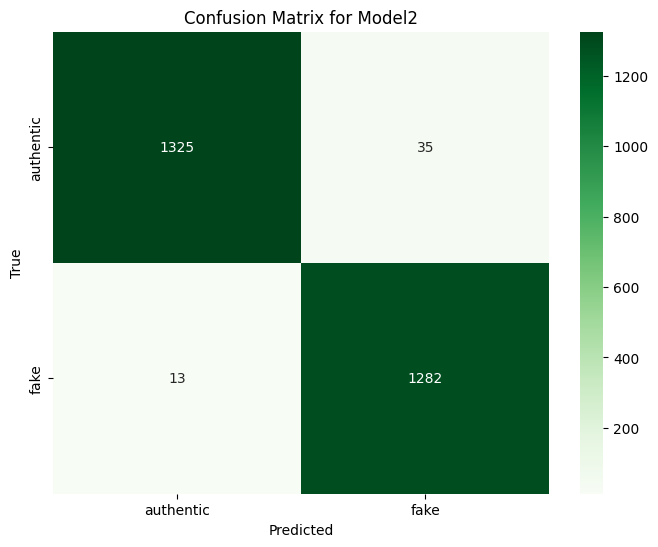

In [ ]:
import torch
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure model2 is in evaluation mode
model2_trained.eval()

all_preds_model2 = []
all_labels_model2 = []

# No need to track gradients for evaluation
with torch.no_grad():
    for inputs, labels in dataloaders['val']:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model2_trained(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds_model2.extend(preds.cpu().numpy())
        all_labels_model2.extend(labels.cpu().numpy())

# Convert lists to numpy arrays
all_preds_model2 = np.array(all_preds_model2)
all_labels_model2 = np.array(all_labels_model2)

# Calculate metrics for model2
accuracy_model2 = accuracy_score(all_labels_model2, all_preds_model2)
precision_model2 = precision_score(all_labels_model2, all_preds_model2, average='weighted')
recall_model2 = recall_score(all_labels_model2, all_preds_model2, average='weighted')
f1_model2 = f1_score(all_labels_model2, all_preds_model2, average='weighted')

print(f"\n--- Model2 Evaluation Statistics ---")
print(f"Overall Accuracy: {accuracy_model2:.4f}")
print(f"Weighted Precision: {precision_model2:.4f}")
print(f"Weighted Recall: {recall_model2:.4f}")
print(f"Weighted F1-Score: {f1_model2:.4f}")

# Classification report for model2
print("\nClassification Report for Model2:")
print(classification_report(all_labels_model2, all_preds_model2, target_names=class_names))

# Confusion Matrix for model2
print("\nConfusion Matrix for Model2:")
cm_model2 = confusion_matrix(all_labels_model2, all_preds_model2)
print(cm_model2)

# Display the confusion matrix with labels for model2
plt.figure(figsize=(8, 6))
sns.heatmap(cm_model2, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix for Model2')
plt.show()

In [ ]:
import torch
import os

# Define the path where you want to save model2 in Google Drive
model2_save_path = '/content/drive/MyDrive/Clonedqrdetector/best_microdot_cnn_model2.pth'

# Ensure the directory exists
os.makedirs(os.path.dirname(model2_save_path), exist_ok=True)

# Save the model's state dictionary
torch.save(model2_trained.state_dict(), model2_save_path)

print(f"Model 2 saved successfully to: {model2_save_path}")

Model 2 saved successfully to: /content/drive/MyDrive/Clonedqrdetector/best_microdot_cnn_model2.pth


In [ ]:
import torchvision.models as models

# Load the pre-trained MobileNetV3-Small model
model_mobilenet = models.mobilenet_v3_small(pretrained=True)

# Freeze all parameters in the feature extractor
# for param in model_mobilenet.features.parameters():
#     param.requires_grad = False

# Modify the classifier for our 2 classes
# The classifier in MobileNetV3-Small is nn.Sequential(Linear(in_features, out_features))
# We need to replace the last linear layer.
num_ftrs = model_mobilenet.classifier[-1].in_features
model_mobilenet.classifier[-1] = nn.Linear(num_ftrs, 2)

# Move the model to the appropriate device (GPU if available)
model_mobilenet = model_mobilenet.to(device)

# Define optimizer for the new model
optimizer_mobilenet = optim.Adam(model_mobilenet.parameters(), lr=0.001) # Start with a slightly lower LR

# Train the MobileNetV3 model with the curriculum learning function
# The train_curriculum_model function already handles epochs and early stopping
print("\n--- Training MobileNetV3 Model ---")
model_mobilenet_trained = train_curriculum_model(model_mobilenet, criterion, optimizer_mobilenet, num_epochs=30)

print("\nMobileNetV3 model training complete!")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Small_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



--- Training MobileNetV3 Model ---

Epoch 1/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.2440 Acc: 0.8925
Val Loss: 0.1295 Acc: 0.9469

Epoch 2/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.1049 Acc: 0.9585
Val Loss: 0.0676 Acc: 0.9736

Epoch 3/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.0777 Acc: 0.9687
Val Loss: 0.0538 Acc: 0.9774

Epoch 4/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learning Rate to prevent Catastrophic Forgetting...
Train Loss: 0.0627 Acc: 0.9748
Val Loss: 0.0798 Acc: 0.9680
Early stopping check: No improvement for 1 epochs.

Epoch 5/30
----------
 Curriculum: HARD MODE (Adding noise, blur, and rotation!)
 Reducing Learn

In [ ]:
import torch
import os

# Define the path where you want to save the MobileNetV3 model in Google Drive
mobilenet_save_path = '/content/drive/MyDrive/Clonedqrdetector/best_mobilenet_v3_model.pth'

# Ensure the directory exists
os.makedirs(os.path.dirname(mobilenet_save_path), exist_ok=True)

# Save the model's state dictionary
torch.save(model_mobilenet_trained.state_dict(), mobilenet_save_path)

print(f"MobileNetV3 model saved successfully to: {mobilenet_save_path}")

MobileNetV3 model saved successfully to: /content/drive/MyDrive/Clonedqrdetector/best_mobilenet_v3_model.pth



--- MobileNetV3 Evaluation Statistics ---
Overall Accuracy: 0.9947
Weighted Precision: 0.9947
Weighted Recall: 0.9947
Weighted F1-Score: 0.9947

Classification Report for MobileNetV3:
              precision    recall  f1-score   support

   authentic       0.99      0.99      0.99      1360
        fake       0.99      0.99      0.99      1295

    accuracy                           0.99      2655
   macro avg       0.99      0.99      0.99      2655
weighted avg       0.99      0.99      0.99      2655


Confusion Matrix for MobileNetV3:
[[1353    7]
 [   7 1288]]


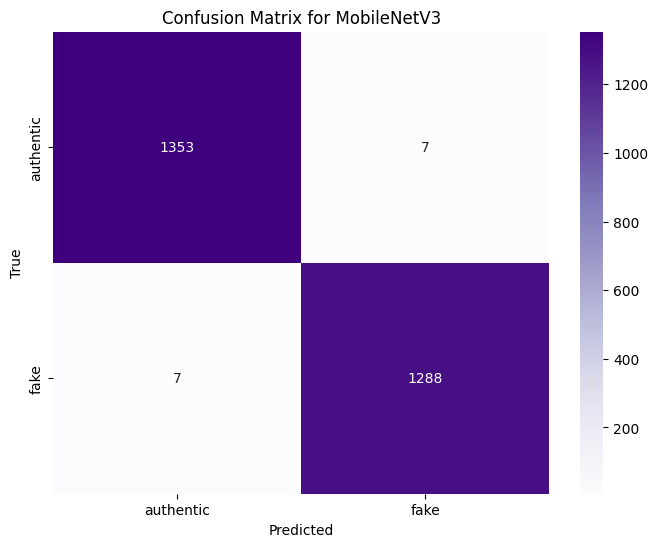

In [ ]:
import torch
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure model_mobilenet_trained is in evaluation mode
model_mobilenet_trained.eval()

all_preds_mobilenet = []
all_labels_mobilenet = []

# No need to track gradients for evaluation
with torch.no_grad():
    for inputs, labels in dataloaders['val']:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model_mobilenet_trained(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds_mobilenet.extend(preds.cpu().numpy())
        all_labels_mobilenet.extend(labels.cpu().numpy())

# Convert lists to numpy arrays
all_preds_mobilenet = np.array(all_preds_mobilenet)
all_labels_mobilenet = np.array(all_labels_mobilenet)

# Calculate metrics for MobileNetV3
accuracy_mobilenet = accuracy_score(all_labels_mobilenet, all_preds_mobilenet)
precision_mobilenet = precision_score(all_labels_mobilenet, all_preds_mobilenet, average='weighted')
recall_mobilenet = recall_score(all_labels_mobilenet, all_preds_mobilenet, average='weighted')
f1_mobilenet = f1_score(all_labels_mobilenet, all_preds_mobilenet, average='weighted')

print(f"\n--- MobileNetV3 Evaluation Statistics ---")
print(f"Overall Accuracy: {accuracy_mobilenet:.4f}")
print(f"Weighted Precision: {precision_mobilenet:.4f}")
print(f"Weighted Recall: {recall_mobilenet:.4f}")
print(f"Weighted F1-Score: {f1_mobilenet:.4f}")

# Classification report for MobileNetV3
print("\nClassification Report for MobileNetV3:")
print(classification_report(all_labels_mobilenet, all_preds_mobilenet, target_names=class_names))

# Confusion Matrix for MobileNetV3
print("\nConfusion Matrix for MobileNetV3:")
cm_mobilenet = confusion_matrix(all_labels_mobilenet, all_preds_mobilenet)
print(cm_mobilenet)

# Display the confusion matrix with labels for MobileNetV3
plt.figure(figsize=(8, 6))
sns.heatmap(cm_mobilenet, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix for MobileNetV3')
plt.show()

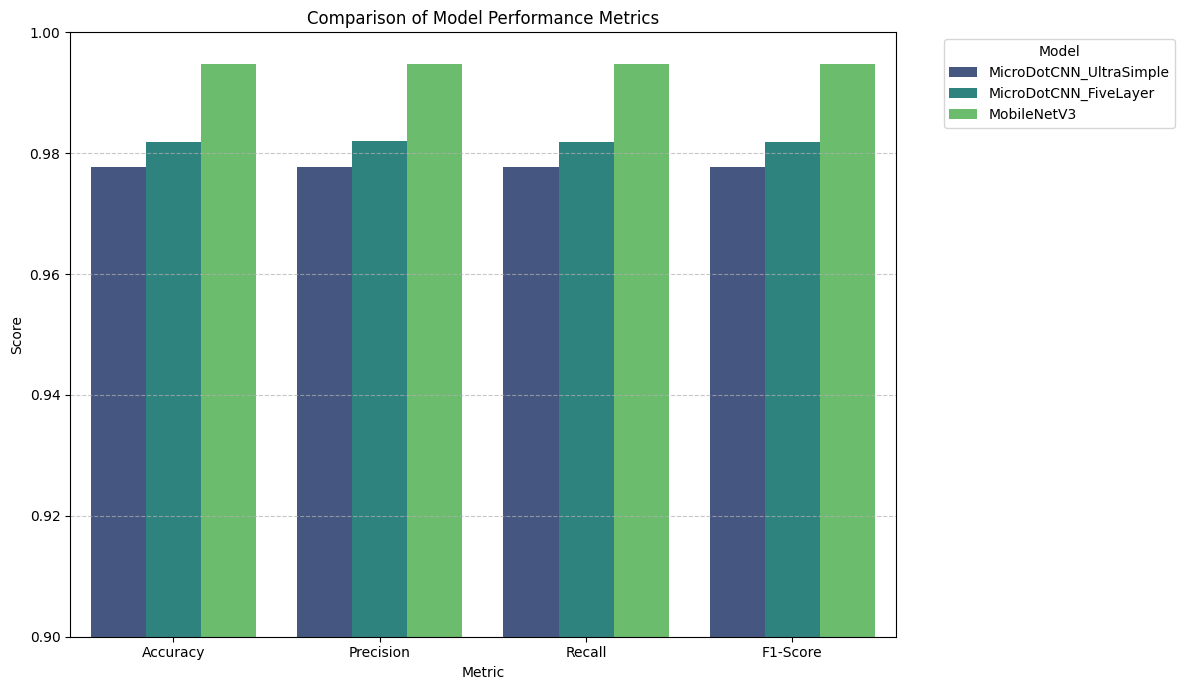


Detailed Metrics:
                         Accuracy  Precision  Recall  F1-Score
Model                                                         
MicroDotCNN_UltraSimple    0.9778     0.9778  0.9778    0.9778
MicroDotCNN_FiveLayer      0.9819     0.9821  0.9819    0.9819
MobileNetV3                0.9947     0.9947  0.9947    0.9947


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Data for the three models
model_names = ['MicroDotCNN_UltraSimple', 'MicroDotCNN_FiveLayer', 'MobileNetV3']

# Metrics from the kernel state
accuracies = [accuracy, accuracy_model2, accuracy_mobilenet]
precisions = [precision, precision_model2, precision_mobilenet]
recalls = [recall, recall_model2, recall_mobilenet]
f1_scores = [f1, f1_model2, f1_mobilenet]

# Create a DataFrame for plotting
data = {
    'Model': model_names,
    'Accuracy': accuracies,
    'Precision': precisions,
    'Recall': recalls,
    'F1-Score': f1_scores
}
metrics_df = pd.DataFrame(data)

# Melt the DataFrame for easy plotting with seaborn
metrics_melted = metrics_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 7))
sns.barplot(x='Metric', y='Score', hue='Model', data=metrics_melted, palette='viridis')
plt.ylim(0.9, 1.0) # Focus on the higher performance range
plt.title('Comparison of Model Performance Metrics')
plt.ylabel('Score')
plt.xlabel('Metric')
plt.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\nDetailed Metrics:")
print(metrics_df.set_index('Model').round(4))